In [31]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler



In [7]:
df = sns.load_dataset("titanic")
print(df.shape)
print(df.head())

(891, 15)
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [4]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [9]:
df["age"]=df["age"].fillna(df["age"].mean())
df["embarked"]=df["embarked"].fillna(df["embarked"].mode()[0])

df=df.drop("deck",axis=1)

In [10]:
print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [12]:
df.shape

(891, 14)

In [15]:
df["FamilySize"] = df["sibsp"] + df["parch"] + 1
df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[0,12,18,60,100],
    labels=["Child","Teen","Adult","Senior"]
)

display(df[["age","FamilySize","AgeGroup"]].head())

,age,FamilySize,AgeGroup
0,22.0,2,Adult
1,38.0,2,Adult
2,26.0,1,Adult
3,35.0,2,Adult
4,35.0,1,Adult


In [24]:
le = LabelEncoder()
df["sex"] = le.fit_transform(df["sex"])
print(df["sex"].head())

0    0
1    0
2    0
3    0
4    0
Name: sex, dtype: int64


In [28]:
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,FamilySize,AgeGroup
0,0,3,0,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,2,Adult
1,1,1,0,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,2,Adult
2,1,3,0,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,1,Adult
3,1,1,0,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,2,Adult
4,0,3,0,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,1,Adult


In [29]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
num_cols = ["age", "sibsp", "parch", "fare"]
df[num_cols] = ss.fit_transform(df[num_cols])

In [30]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,FamilySize,AgeGroup
0,0,3,0,-0.592481,0.432793,-0.473674,-0.502445,S,Third,man,True,Southampton,no,False,2,Adult
1,1,1,0,0.638789,0.432793,-0.473674,0.786845,C,First,woman,False,Cherbourg,yes,False,2,Adult
2,1,3,0,-0.284663,-0.474545,-0.473674,-0.488854,S,Third,woman,False,Southampton,yes,True,1,Adult
3,1,1,0,0.407926,0.432793,-0.473674,0.420730,S,First,woman,False,Southampton,yes,False,2,Adult
4,0,3,0,0.407926,-0.474545,-0.473674,-0.486337,S,Third,man,True,Southampton,no,True,1,Adult



Missing values after cleaning: 2
Final shape: (891, 16)
Mean of scaled cols: {'age': 0.0, 'sibsp': 0.0, 'parch': 0.0, 'fare': 0.0}
Std of scaled cols : {'age': 1.0, 'sibsp': 1.0, 'parch': 1.0, 'fare': 1.0}

Clean, model-ready dataset:
    survived  pclass  sex     age   sibsp   parch    fare embarked  class  \
0         0       3    0 -0.5925  0.4328 -0.4737 -0.5024        S  Third   
1         1       1    0  0.6388  0.4328 -0.4737  0.7868        C  First   
2         1       3    0 -0.2847 -0.4745 -0.4737 -0.4889        S  Third   
3         1       1    0  0.4079  0.4328 -0.4737  0.4207        S  First   
4         0       3    0  0.4079 -0.4745 -0.4737 -0.4863        S  Third   

     who  adult_male  embark_town alive  alone  FamilySize AgeGroup  
0    man        True  Southampton    no  False           2    Adult  
1  woman       False    Cherbourg   yes  False           2    Adult  
2  woman       False  Southampton   yes   True           1    Adult  
3  woman       False  Sout

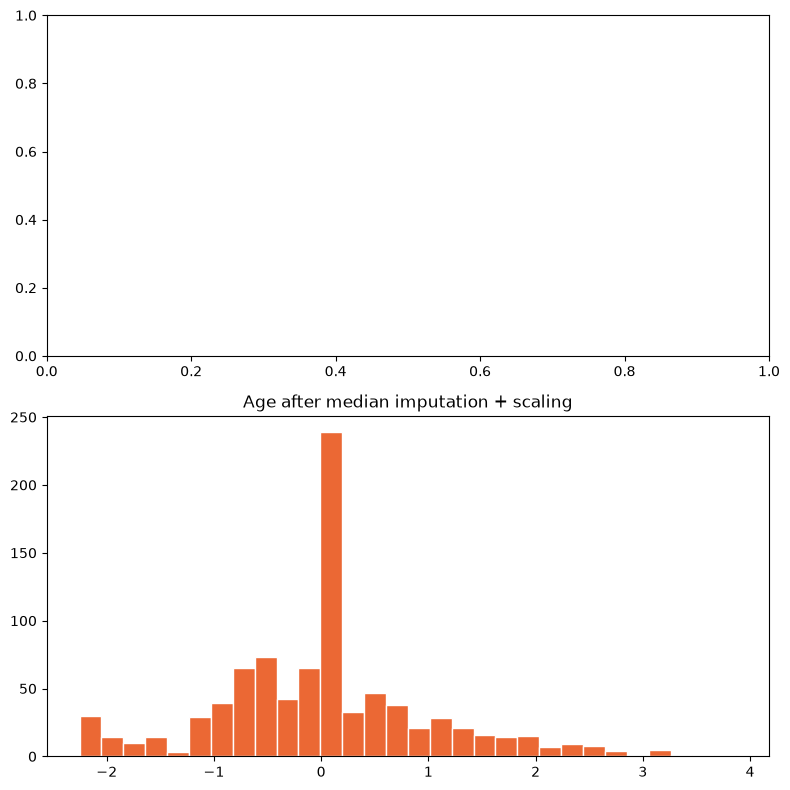

In [34]:
print("\nMissing values after cleaning:", int(df.isnull().sum().sum()))
print("Final shape:", df.shape)
print("Mean of scaled cols:", df[num_cols].mean().round(4).to_dict())
print("Std of scaled cols :", df[num_cols].std(ddof=0).round(4).to_dict())
print("\nClean, model-ready dataset:\n", df.head().round(4))

fig, ax = plt.subplots(2, 1, figsize=(8, 8))
ax[1].hist(df["age"], bins=30, color="#eb6834", edgecolor="white"); ax[1].set_title("Age after median imputation + scaling")
plt.tight_layout()